## Primer paso: crear los dataset .csv de (AAEC, ArGPT, MTC, AASS)

In [1]:
import pandas as pd
from tabulate import tabulate
import networkx as nx
import matplotlib.pyplot as plt

In [2]:
result_path = "./results/minimal_v5/"
path_minimal = "./dataset_minimal/"

### Component

In [3]:
# Cargar el CSV
dfv_train = pd.read_csv(path_minimal + "component_train.csv")
dfv_test = pd.read_csv(path_minimal + "component_test.csv")
dfv_value = pd.read_csv(path_minimal + "component_val.csv")

In [7]:
# Misturamos todo
dfc = pd.concat(
    [dfv_train, dfv_test, dfv_value],
    ignore_index=True
)
# dfc

In [5]:
# Revisar os componentes por text_id
columna = "text_id"
# df_filter = dfc[dfc[columna] == "ArGPT_96"]
# print(df_filter.shape)
# df_filter

In [8]:
conteo = (
    dfc[columna]
    .drop_duplicates()
    .str.rsplit("_", n=1).str[0]
    .value_counts()
    .reset_index()
)

conteo.columns = ["valor", "cantidad"]

conteo["porcentaje"] = (
    conteo["cantidad"] / len(dfc[columna].drop_duplicates()) * 100
).round(2)

# conteo
print(tabulate(conteo.reset_index(), headers='keys', tablefmt='rounded_outline', showindex=False))
total = conteo["cantidad"].sum()
print("Total:", total)

╭─────────┬──────────────────┬────────────┬──────────────╮
│   index │ valor            │   cantidad │   porcentaje │
├─────────┼──────────────────┼────────────┼──────────────┤
│       0 │ CDCP             │        730 │        34.03 │
│       1 │ AbstRCT_neoplasm │        500 │        23.31 │
│       2 │ AAEC             │        402 │        18.74 │
│       3 │ ArGPT            │        172 │         8.02 │
│       4 │ MTC              │        112 │         5.22 │
│       5 │ AbstRCT_glaucoma │        100 │         4.66 │
│       6 │ AbstRCT_mixed    │         69 │         3.22 │
│       7 │ AASD             │         60 │         2.8  │
╰─────────┴──────────────────┴────────────┴──────────────╯
Total: 2145


In [54]:
indice_tableta_dataset = 2
name_dataset = conteo["valor"][indice_tableta_dataset]

# Só ids dos componentes
dfc_name_dataset = dfc[dfc[columna].str.contains(name_dataset, na=False)].copy()
dfc_name_dataset_summary = (
    dfc_name_dataset.groupby(columna)
       .size()
       .reset_index(name="seg")
)

print(dfc_name_dataset_summary.shape)
dfc_name_dataset_summary

(402, 2)


,text_id,seg
0,AAEC_001,11
1,AAEC_002,14
2,AAEC_003,10
3,AAEC_004,11
4,AAEC_005,12
...,...,...
397,AAEC_398,16
398,AAEC_399,10
399,AAEC_400,10
400,AAEC_401,10


In [55]:
# Obtener o revisar el nodo por text_id
def get_nodes(text_id):
    dfc_filter = dfc[dfc[columna].str.contains(text_id, na=False)].copy()
    return dfc_filter

dfc_filter = get_nodes("AAEC_001")
print(dfc_filter.shape)
dfc_filter

(11, 6)


,text_id,component_id,component_text,full_text,label,minimalist_labels
741,AAEC_001,AAEC_001_0,we should attach more importance to cooperatio...,Should students be taught to compete or to coo...,MajorClaim,MajorClaim
742,AAEC_001,AAEC_001_1,a more cooperative attitudes towards life is m...,Should students be taught to compete or to coo...,MajorClaim,MajorClaim
743,AAEC_001,AAEC_001_2,"through cooperation, children can learn about ...",Should students be taught to compete or to coo...,Claim,Premise
744,AAEC_001,AAEC_001_3,What we acquired from team work is not only ho...,Should students be taught to compete or to coo...,Premise,Premise
745,AAEC_001,AAEC_001_4,"During the process of cooperation, children ca...",Should students be taught to compete or to coo...,Premise,Premise
746,AAEC_001,AAEC_001_5,All of these skills help them to get on well w...,Should students be taught to compete or to coo...,Premise,Premise
747,AAEC_001,AAEC_001_6,competition makes the society more effective,Should students be taught to compete or to coo...,Claim,Premise
748,AAEC_001,AAEC_001_7,the significance of competition is that how to...,Should students be taught to compete or to coo...,Premise,Premise
749,AAEC_001,AAEC_001_8,when we consider about the question that how t...,Should students be taught to compete or to coo...,Premise,Premise
750,AAEC_001,AAEC_001_9,Take Olympic games which is a form of competit...,Should students be taught to compete or to coo...,Premise,Premise


### Relation

In [56]:
# Cargar el CSV
dfr_train = pd.read_csv(path_minimal + "relation_train.csv")
dfr_test = pd.read_csv(path_minimal + "relation_test.csv")
dfr_val = pd.read_csv(path_minimal + "relation_val.csv")
dfr = pd.concat(
    [dfr_train, dfr_test, dfr_val],
    ignore_index=True
)
print(dfr.shape)
dfr

(14740, 7)


,text_id,source_id,source_text,target_id,target_text,label,minimalist_labels
0,AAEC_001,AAEC_001_10,"without the cooperation, there would be no vic...",AAEC_001_0,we should attach more importance to cooperatio...,For,support
1,AAEC_001,AAEC_001_10,"without the cooperation, there would be no vic...",AAEC_001_1,a more cooperative attitudes towards life is m...,For,support
2,AAEC_001,AAEC_001_2,"through cooperation, children can learn about ...",AAEC_001_0,we should attach more importance to cooperatio...,For,support
3,AAEC_001,AAEC_001_2,"through cooperation, children can learn about ...",AAEC_001_1,a more cooperative attitudes towards life is m...,For,support
4,AAEC_001,AAEC_001_3,What we acquired from team work is not only ho...,AAEC_001_2,"through cooperation, children can learn about ...",supports,support
...,...,...,...,...,...,...,...
14735,CDCP_01256,CDCP_01256_1,as FICO (the industry standard) uses proprieta...,CDCP_01256_0,Collectors should be barred from stating that ...,reason,support
14736,CDCP_01274,CDCP_01274_2,because creditors seldom have system capabili...,CDCP_01274_1,"For example, if a creditor obtains a judgment...",reason,support
14737,CDCP_01282,CDCP_01282_3,so the consumer has at least a fighting chanc...,CDCP_01282_2,They need to be required to identify themselv...,reason,support
14738,CDCP_01282,CDCP_01282_5,because I have a fairly common last name.,CDCP_01282_4,In my case I have no debts of my own but am c...,reason,support


In [57]:
# Obtener o revisar as relações por text_id
def get_edges(text_id):
    dfr_filter = dfr[dfr[columna] == text_id]
    dfr_filter = dfr_filter.dropna()
    return dfr_filter

dfr_filter = get_edges("AAEC_001")
print(dfr_filter.shape)
dfr_filter

(12, 7)


,text_id,source_id,source_text,target_id,target_text,label,minimalist_labels
0,AAEC_001,AAEC_001_10,"without the cooperation, there would be no vic...",AAEC_001_0,we should attach more importance to cooperatio...,For,support
1,AAEC_001,AAEC_001_10,"without the cooperation, there would be no vic...",AAEC_001_1,a more cooperative attitudes towards life is m...,For,support
2,AAEC_001,AAEC_001_2,"through cooperation, children can learn about ...",AAEC_001_0,we should attach more importance to cooperatio...,For,support
3,AAEC_001,AAEC_001_2,"through cooperation, children can learn about ...",AAEC_001_1,a more cooperative attitudes towards life is m...,For,support
4,AAEC_001,AAEC_001_3,What we acquired from team work is not only ho...,AAEC_001_2,"through cooperation, children can learn about ...",supports,support
5,AAEC_001,AAEC_001_4,"During the process of cooperation, children ca...",AAEC_001_2,"through cooperation, children can learn about ...",supports,support
6,AAEC_001,AAEC_001_5,All of these skills help them to get on well w...,AAEC_001_2,"through cooperation, children can learn about ...",supports,support
7,AAEC_001,AAEC_001_6,competition makes the society more effective,AAEC_001_0,we should attach more importance to cooperatio...,Against,attack
8,AAEC_001,AAEC_001_6,competition makes the society more effective,AAEC_001_1,a more cooperative attitudes towards life is m...,Against,attack
9,AAEC_001,AAEC_001_7,the significance of competition is that how to...,AAEC_001_6,competition makes the society more effective,supports,support


### Build graph

In [58]:
# Preparar dfc_resultado_component con solo las columnas necesarias
def get_data_graph(dfc_component, dfr_relation):

    dfc_component = dfc_component.rename(columns={
        "label": "labels_component",
        "minimalist_labels": "minimalist_labels_component"
    })

    dfr_relation = dfr_relation.rename(columns={
        "label": "labels_relation",
    })
    
    dfr_relation = dfr_relation.merge(
        dfc_component[['component_id', 'labels_component', 'minimalist_labels_component']],
        left_on='source_id',
        right_on='component_id',
        how='left'
    )

    dfr_relation = dfr_relation.rename(columns={
        "labels_component": "label_component_source",
        "minimalist_labels_component": "minimal_label_component_source",

    })

    dfr_relation = dfr_relation.merge(
        dfc_component[['component_id', 'labels_component', 'minimalist_labels_component']],
        left_on='target_id',
        right_on='component_id',
        how='left'
    )

    dfr_relation = dfr_relation.rename(columns={
        "labels_component": "label_component_target",
        "minimalist_labels_component": "minimal_label_component_target",

    })

    # Seleccionar solo las columnas que necesitas
    df_merged = dfr_relation[[
        "minimalist_labels",
        "labels_relation",
        "source_id",
        "label_component_source",
        "minimal_label_component_source",
        "target_id",
        "label_component_target",
        "minimal_label_component_target"
    ]]

    return df_merged

In [77]:
# dfg = get_data_graph(dfc_filter, dfr_filter)
# dfg

In [59]:
def crear_grafo(df_nodes, df_sub):  
    # Crear grafo dirigido
    G = nx.DiGraph()

    # 1. Agregar todos los nodos
    for _, row in df_nodes.iterrows():
        G.add_node(
            row["component_id"],
            component=row["minimalist_labels"]
        )
    # 2. Agregar las relaciones
    for _, row in df_sub.iterrows():
        G.add_edge(row["target_id"], row["source_id"], label=row["minimalist_labels"])

    n_nodes = G.number_of_nodes()
    n_edges = G.number_of_edges()
    n_isolates = nx.number_of_isolates(G)
    n_comp = nx.number_weakly_connected_components(G)
    n_root = len([n for n, d in G.in_degree() if d == 0])
    is_directed_acyclic_graph = nx.is_directed_acyclic_graph(G)
    is_connected = nx.is_weakly_connected(G)
    is_tree = nx.is_tree(G)
    is_arborescence = nx.is_arborescence(G)
    is_forest = nx.is_forest(G)
    
    return G, n_nodes, n_edges, n_isolates, n_comp, n_root, is_directed_acyclic_graph, is_connected, is_tree, is_arborescence, is_forest

def plot_grafo(text_id, G):
    # Cor por nó
    color_nodo = {
        "MajorClaim" : "#e74c3c",   # Vermelho
        "Claim"      : "#3498db",   # Azul
        "Premise"    : "#2ecc71",   # Verde
    }
    node_colors = [
        color_nodo.get(G.nodes[n].get("component", ""), "#95a5a6")
        for n in G.nodes()
    ]

    colores_label = {
        "support" : "#27ae60",   # Verde oscuro
        "attack"  : "#c0392b",   # Vermelho oscuro
    }
    edge_colors   = [colores_label.get(d["label"], "gray") for _, _, d in G.edges(data=True)]
    
    plt.figure(figsize=(14, 10))
    pos = nx.spring_layout(G, seed=42, k=30, iterations=100)
    
    # Etiquetas de nodos con ID + tipo de componente
    node_labels = {
        n: f"{n}\n{G.nodes[n].get('component', '')}"
        for n in G.nodes()
    }

    nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=2000)
    nx.draw_networkx_labels(G, pos, labels=node_labels, font_color="black", font_size=8, font_weight="bold")
    nx.draw_networkx_edges(
        G, pos,
        edge_color=edge_colors,
        arrows=True, arrowsize=25, arrowstyle="-|>",
        width=2, connectionstyle="arc3,rad=0.1",
        min_source_margin=30, min_target_margin=30,
    )
    
    edge_labels = nx.get_edge_attributes(G, "label")
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7, font_color="darkgreen")
    
    from matplotlib.lines import Line2D
    leyenda = [
        Line2D([0], [0], color="green", linewidth=2, label="support"),
        Line2D([0], [0], color="red",   linewidth=2, label="attack"),
        Line2D([0], [0], color="gray",  linewidth=2, label="otros"),
    ]
    plt.legend(handles=leyenda, loc="upper left", fontsize=9)
    plt.title(f"Grafo argumentativo: {text_id}", fontsize=14)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

### Preparate info to graph

In [62]:
info = "info"
g = "graph"
n_node = "n_nodes"
n_edge = "n_edges"
n_isol = "n_isolates"
n_comp = "n_comp"
n_root = "n_root"
is_acyclic = "is_acyclic"
is_connected = "is_connected"
is_tree = "is_tree"
is_arborescence = "is_arborescence"
is_forest = "is_forest"



dfc_name_dataset_summary[info] = None
dfc_name_dataset_summary[g] = None
dfc_name_dataset_summary[n_node] = None
dfc_name_dataset_summary[n_edge] = None
dfc_name_dataset_summary[n_isol] = None
dfc_name_dataset_summary[n_comp] = None
dfc_name_dataset_summary[n_root] = None
dfc_name_dataset_summary[is_acyclic] = None
dfc_name_dataset_summary[is_connected] = None
dfc_name_dataset_summary[is_tree] = None
dfc_name_dataset_summary[is_arborescence] = None
dfc_name_dataset_summary[is_forest] = None

for idx, component_id in dfc_name_dataset_summary[columna].items():
    df_nodes = get_nodes(component_id)
    df_edges = get_edges(component_id)
    df_graph = get_data_graph(df_nodes, df_edges)
    graph, n_nodes, n_edges, n_isolates, n_compts, n_rootes, acyclic, connected, tree, arborescence, forest = crear_grafo(df_nodes, df_graph)
    dfc_name_dataset_summary.at[idx, info] = df_graph
    dfc_name_dataset_summary.at[idx, g] = graph
    dfc_name_dataset_summary.at[idx, n_node] = n_nodes
    dfc_name_dataset_summary.at[idx, n_edge] = n_edges
    dfc_name_dataset_summary.at[idx, n_isol] = n_isolates
    dfc_name_dataset_summary.at[idx, n_comp] = n_compts
    dfc_name_dataset_summary.at[idx, n_root] = n_rootes
    dfc_name_dataset_summary[is_acyclic] = acyclic
    dfc_name_dataset_summary[is_connected] = connected
    dfc_name_dataset_summary[is_tree] = tree
    dfc_name_dataset_summary[is_arborescence] = arborescence
    dfc_name_dataset_summary[is_forest] = forest

In [63]:
id_text_busca = "AAEC_001"
# dfc_name_dataset_summary.to_pickle(result_path + "CDCP_Minimal_Grafo.pkl")
result = dfc_name_dataset_summary[dfc_name_dataset_summary[columna] == id_text_busca]
result

,text_id,seg,info,graph,n_nodes,n_edges,n_isolates,n_comp,is_acyclic,is_connected,is_tree,is_arborescence,is_forest,n_root
0,AAEC_001,11,minimalist_labels labels_relation source...,"(AAEC_001_0, AAEC_001_1, AAEC_001_2, AAEC_001_...",11,12,0,1,True,True,False,False,False,2


In [39]:
result_info = result.iloc[0]
result_info["info"]
# df_decribe = result_info["info"][["source_id", "label_component_source", "minimal_label_component_source", ]]
print(tabulate(result_info["info"].reset_index(), headers='keys', tablefmt='rounded_outline', showindex=False))

╭─────────┬─────────────────────┬───────────────────┬─────────────┬──────────────────────────┬──────────────────────────────────┬─────────────┬──────────────────────────┬──────────────────────────────────╮
│   index │ minimalist_labels   │ labels_relation   │ source_id   │ label_component_source   │ minimal_label_component_source   │ target_id   │ label_component_target   │ minimal_label_component_target   │
├─────────┼─────────────────────┼───────────────────┼─────────────┼──────────────────────────┼──────────────────────────────────┼─────────────┼──────────────────────────┼──────────────────────────────────┤
│       0 │ support             │ For               │ AAEC_001_10 │ Claim                    │ Premise                          │ AAEC_001_0  │ MajorClaim               │ MajorClaim                       │
│       1 │ support             │ For               │ AAEC_001_10 │ Claim                    │ Premise                          │ AAEC_001_1  │ MajorClaim               │ Major

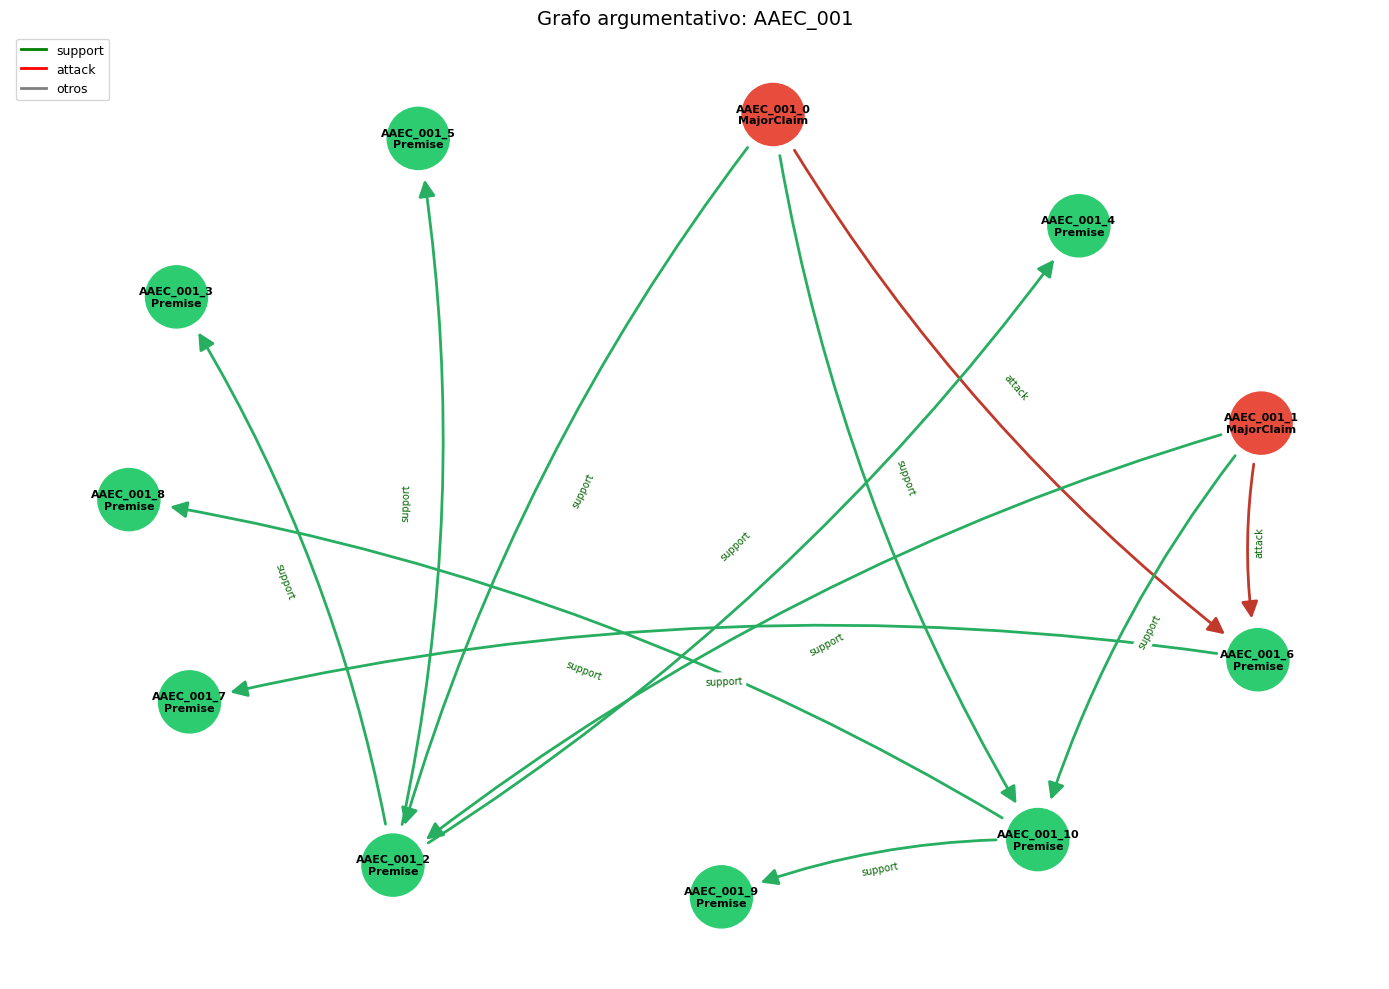

In [40]:
plot_grafo(id_text_busca, result_info["graph"])